<p align="center"><b><font size="5">Predicción de Churn de telecomunicaciones con modelos clásicos de machine learning y redes neuronales</font></b></p>

<p align="center"><b><font size="4">Descripción general:</font></b></p>

La meta del proyecto es predecir el abandono de clientes de una compañía de Telecomunicaciones y desarrollar una aplicación con el mejor modelo. Se usan las siguientes ténicas:

- Logistic Regresion.
- Random Forest.
- XGBoost.
- Feedforward Neural Network (FNN)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.metrics import recall_score, precision_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import torch
import torch.nn as nn
import torch.optim as optim


<p align="center"><b><font size="4">Descarga y exploración del Dataset</font></b></p>

Se descarga el dataset y se explora: valores faltantes, duplicados, distribución, correlaciones y las principales características del mismo.

In [2]:
data = pd.read_csv('Customer Churn.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [3]:
data.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [4]:
data.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [5]:
data.isna().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

In [6]:
data.duplicated().sum()

np.int64(300)

In [3]:
data=data.drop_duplicates()

In [8]:
data['Churn'].value_counts(normalize= True)*100

Churn
0    84.350877
1    15.649123
Name: proportion, dtype: float64

In [9]:
data.shape

(2850, 14)

In [10]:
corr = data.corr(numeric_only=True)["Churn"].sort_values(ascending=False)
print(corr)

Churn                      1.000000
Complains                  0.546055
Status                     0.492867
Call  Failure              0.003310
Age Group                 -0.005891
Age                       -0.011491
Subscription  Length      -0.037984
Tariff Plan               -0.106000
Charge  Amount            -0.201662
Frequency of SMS          -0.218894
Distinct Called Numbers   -0.270343
Customer Value            -0.287078
Seconds of Use            -0.295999
Frequency of use          -0.298608
Name: Churn, dtype: float64


El dataset presentó 300 datos duplicados y un target desequilibrado. La correlación nos permite plantear una hipótesis inicial: El abandono del servicio muestra alguna relación con la cantidad de quejas y el estatus del cliente. Mientras que a mayor uso del servicio parece disminuir la probabilidad de abandono.

<p align="center"><b><font size="4">Preprocesamiento: Manejar valores atípicos y normalización</font></b></p>

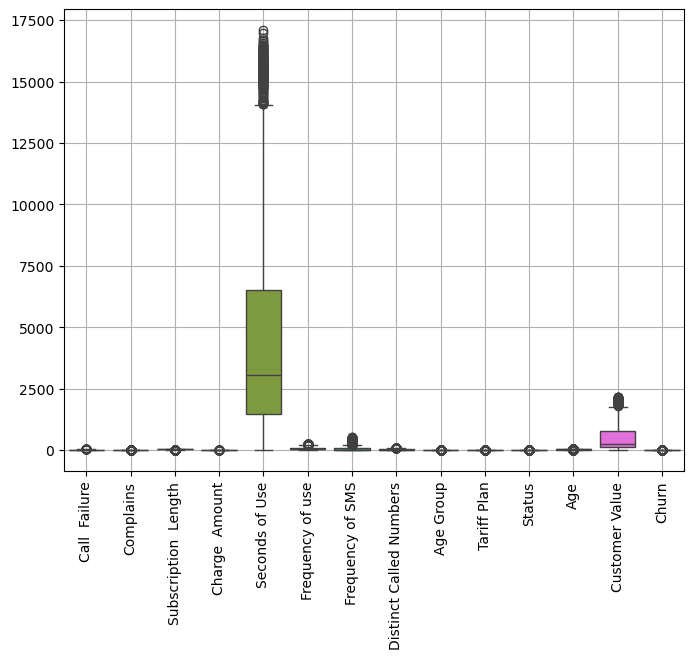

In [11]:
plt.figure(figsize=(8,6))
sns.boxplot(data)
plt.xticks(rotation=90)
plt.grid()
plt.show()

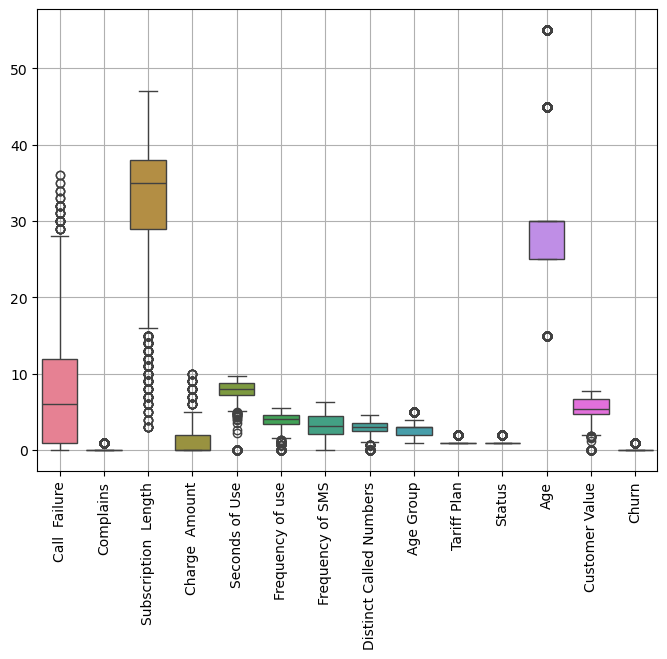

In [4]:
col=['Distinct Called Numbers', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Customer Value']
data[col] = np.log1p(data[col])
plt.figure(figsize=(8,6))
sns.boxplot(data)
plt.xticks(rotation=90)
plt.grid()
plt.show()

La transformación logarítmica disminuyó considerablemente el impacto de los valores atípicos por lo que se probará los modelos en este estado. Las columnas Status y Tariff Plan son binarias en 1 y 2. Se remapean a 0 y 1 y se normalizan las columnas numéricas.

In [6]:
data['Tariff Plan'] = data['Tariff Plan'].map({1:0, 2:1})
data['Status'] = data['Status'].map({1:0, 2:1})

x = data.drop('Churn', axis=1)
y = data['Churn']

In [14]:
col = ['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age',
       'Customer Value']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify=y, random_state=42)

scaler = MinMaxScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[col] = scaler.fit_transform(x_train[col])
x_test_scaled[col] = scaler.transform(x_test[col])

<p align="center"><b><font size="4">Entrenar los modelos: Regresión logística, Random Forest y XGboost.</font></b></p>

Al estar las clases desbalanceadas se ajustan los modelos para manejar esta característica del dataset. La estadística principal será Recall, considerando que los falsos negativos suelen ser más costosos en términos de abandono de servicios, aunque se busca un equilibrio entre todas las estadísticas. 

In [15]:
y.value_counts(normalize= True)

Churn
0    0.843509
1    0.156491
Name: proportion, dtype: float64

In [16]:
scale = (y_train.value_counts()[0] / y_train.value_counts()[1])

model_logistic = LogisticRegression(penalty= 'l2', C=1.0, class_weight='balanced')
model_logistic.fit(x_train_scaled, y_train)
y_predict_lr = model_logistic.predict(x_test_scaled)
y_prob_log = model_logistic.predict_proba(x_test_scaled)[:,1]

model_forest = RandomForestClassifier(n_estimators = 300, class_weight='balanced', random_state=42)
model_forest.fit(x_train_scaled, y_train)
y_predict_forest = model_forest.predict(x_test_scaled)
y_prob_forest = model_forest.predict_proba(x_test_scaled)[:,1]

model_boost= XGBClassifier(objective="binary:logistic", scale_pos_weight= scale, learning_rate=0.1, random_state=42)
model_boost.fit(x_train_scaled, y_train)
y_predict_boost = model_boost.predict(x_test_scaled)
y_prob_boost = model_boost.predict_proba(x_test_scaled)[:,1]

predicciones = {'Logistic': (y_predict_lr,y_prob_log), 'Forest': (y_predict_forest,y_prob_forest), 'Boost': (y_predict_boost,y_prob_boost)}
resultados = []


for i,(e,c) in predicciones.items():
    resultados.append({'Modelo':i,
                       'Recall':recall_score(y_test, e),
                       'Accuracy':accuracy_score(y_test, e),
                       'Precisión': precision_score(y_test, e),
                       'F1': f1_score(y_test, e),
                       'ROC':roc_auc_score(y_test, c)})

df_resultados = pd.DataFrame(resultados)
df_resultados

,Modelo,Recall,Accuracy,Precisión,F1,ROC
0,Logistic,0.865169,0.850877,0.513333,0.644351,0.924490
1,Forest,0.797753,0.959649,0.934211,0.860606,0.983835
2,Boost,0.887640,0.947368,0.797980,0.840426,0.983660


Entre Random Forest y XGBoost no hay un claro ganador. Random Forest es un poco más equilibrado teniendo 0.02 de F1 más de XGBoost, pero XGBoost tiene un mejor recall. Tentativamente XGBoost es nuestro mejor modelo por su mayor recall, que se alínea con el objetivo del modelo. 

El siguiente paso es verificar diferentes hiperparámetros con GridSearch de estos dos modelos. 

In [17]:
param_grid_rf = {
    'n_estimators': [100, 200,300],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 2],
    'class_weight': [None, 'balanced']}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring = "recall")
grid.fit(x_train_scaled, y_train)
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test_scaled)

In [18]:
best_model

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [19]:
scale = (y_train.value_counts()[0] / y_train.value_counts()[1])
param_grid_xgb = {
    'n_estimators': [100, 200,],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'scale_pos_weight': [1, scale]}

grid = GridSearchCV(XGBClassifier(objective="binary:logistic", random_state=42), param_grid_xgb, cv=5, scoring = "recall")
grid.fit(x_train_scaled, y_train)
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test_scaled)

In [20]:
best_model

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [21]:
pipeline_smote = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))])

param_grid_rf = {
    'model__n_estimators': [100, 200,300],
    'model__max_depth': [5, 10, None],
    'model__min_samples_leaf': [1, 2],
    'model__class_weight': [None, 'balanced']}

grid = GridSearchCV(pipeline_smote, param_grid_rf, cv=5, scoring = "recall")
grid.fit(x_train_scaled, y_train)
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test_scaled)

In [22]:
best_model

,steps,"[('smote', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2


In [23]:
pipeline_smote = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', XGBClassifier(objective="binary:logistic", random_state=42))])

scale = (y_train.value_counts()[0] / y_train.value_counts()[1])
param_grid_xgb = {
    'model__n_estimators': [100, 200,],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__max_depth': [3, 5],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__scale_pos_weight': [1, scale]}

grid = GridSearchCV(pipeline_smote, param_grid_xgb, cv=5, scoring = "recall")
grid.fit(x_train_scaled, y_train)
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test_scaled)

In [24]:
best_model

,steps,"[('smote', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None


In [25]:
def modelos(modelo, x_train, y_train, x_test, y_test, nombre):
    modelo

    modelo.fit(x_train, y_train)
    y_pred = modelo.predict(x_test)
    y_prob = modelo.predict_proba(x_test)[:,1]
    
    resultados = {}
    resultados = {'Modelo':nombre,
                           'Recall':recall_score(y_test, y_pred),
                           'Accuracy':accuracy_score(y_test, y_pred),
                           'Precisión': precision_score(y_test, y_pred),
                           'F1': f1_score(y_test, y_pred),
                           'ROC':roc_auc_score(y_test, y_prob)}
    
    
    return resultados

In [7]:
scale = (y_train.value_counts()[0] / y_train.value_counts()[1])

forest_normal = RandomForestClassifier(n_estimators = 100, max_depth=5, min_samples_leaf=2,
                                       class_weight='balanced', random_state=42)

forest_smote = RandomForestClassifier(n_estimators = 100, max_depth=5, min_samples_leaf=1, random_state=42)

xgboost_normal = XGBClassifier(objective="binary:logistic", n_estimators=100, learning_rate=0.5, max_depth=3, subsample=0.8,
                              colsample_bytree=0.8, scale_pos_weight=scale, random_state=42)

xgboost_smote = XGBClassifier(objective="binary:logistic", n_estimators=100, learning_rate=0.01, max_depth=5, subsample=0.8,
                              colsample_bytree=0.8, scale_pos_weight=scale, random_state=42)


smote = SMOTE(random_state=42)

x_train_smote, y_train_smote = smote.fit_resample(x_train_scaled, y_train)

In [27]:
modelo_forest_normal =modelos(forest_normal, x_train_scaled, y_train, x_test_scaled, y_test, "Forest")
modelo_xgboost_normal =modelos(xgboost_normal, x_train_scaled, y_train, x_test_scaled, y_test, "XGBoost")
modelo_forest_smote =modelos(forest_smote, x_train_smote, y_train_smote, x_test_scaled, y_test, "Forest_smote")
modelo_xgboost_smote =modelos(xgboost_smote, x_train_smote, y_train_smote, x_test_scaled, y_test, "XGBoost_smote")

datos= [modelo_forest_normal,modelo_xgboost_normal,modelo_forest_smote,modelo_xgboost_smote]
tabla_modelos = pd.DataFrame(datos)
tabla_modelos

,Modelo,Recall,Accuracy,Precisión,F1,ROC
0,Forest,0.910112,0.868421,0.547297,0.683544,0.955150
1,XGBoost,0.865169,0.943860,0.793814,0.827957,0.975998
2,Forest_smote,0.887640,0.861404,0.533784,0.666667,0.955488
3,XGBoost_smote,1.000000,0.642105,0.303754,0.465969,0.952919


Smoote mejoró en XGBoost el recall pero disminuyó mucho la precisión, costo que no lo hace viable. Los modelos con los hiperparámetros base resultaron mejores que con nuestra selección en Gridsearch. Por lo que se selecciona XGBoost con los hiperparámetros base como el mejor modelo. Abajo una matriz de confusión con los resultados.

Para restar complejidad al modelo se verifica si se puede prescindir de algunas columnas sin afectar las métricas. También se prueban diferentes umbrales con convinaciones de learning_rate que maximice el recall con la menor pérdida de precisión en el modelo seleccionado.

<Figure size 100x100 with 0 Axes>

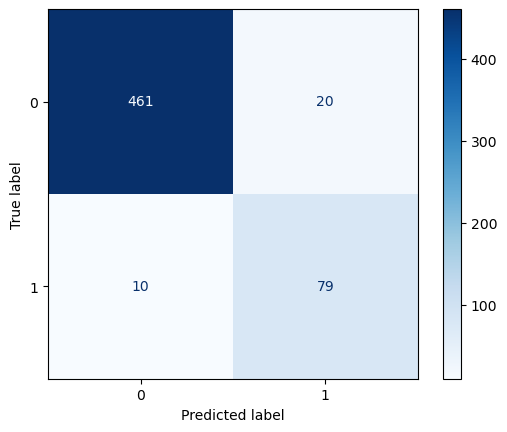

In [28]:
plt.figure(figsize= (1,1))
cm = confusion_matrix(y_test, y_predict_boost)
disp = ConfusionMatrixDisplay(confusion_matrix= cm, display_labels =model_boost.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show()

<p align="center"><b><font size="4">Selección de columnas</font></b></p>
Con el modelo ganador se prueban diferentes configuraciones de columnas, intentando mantener o mejorar las métricas con menos datos.

Se verifica las columnas con mayor peso en la predicción.

In [29]:
importancia = model_boost.feature_importances_
columnas = pd.DataFrame({
    "columnas": x_train.columns,
    "Importancia": importancia
}).sort_values(by="Importancia", ascending=False)

print(columnas)

                   columnas  Importancia
10                   Status     0.528071
1                 Complains     0.212677
8                 Age Group     0.052363
4            Seconds of Use     0.041196
2      Subscription  Length     0.039047
12           Customer Value     0.026078
7   Distinct Called Numbers     0.024509
5          Frequency of use     0.023268
0             Call  Failure     0.019956
6          Frequency of SMS     0.017463
3            Charge  Amount     0.015372
9               Tariff Plan     0.000000
11                      Age     0.000000


Para obtener un conjunto de columnas que disminuya la multicolinealidad se usa una mapa de correlación, aunque XGBoost no se ve afectado en exceso por esto. 

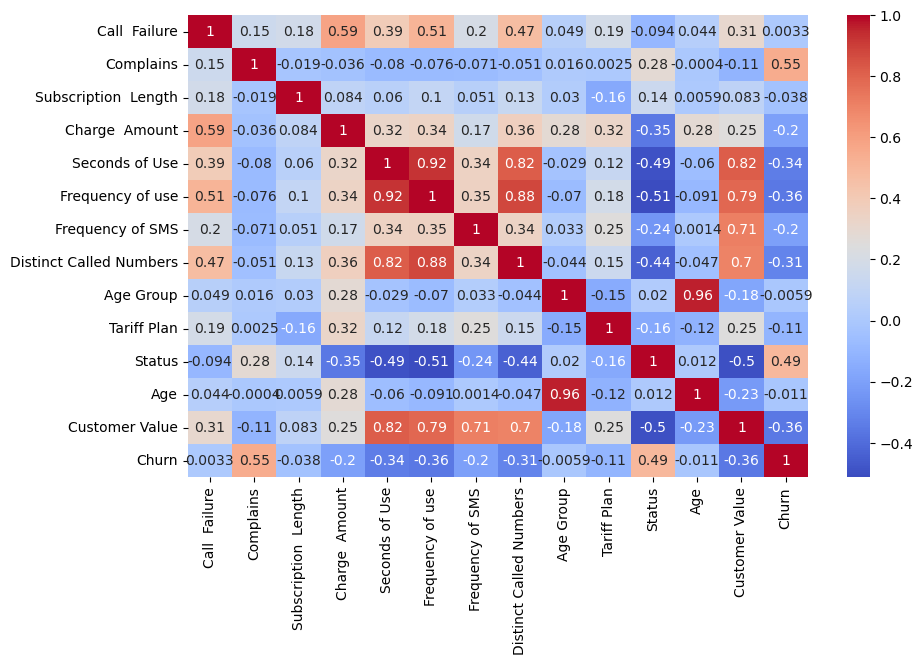

In [30]:
correlacion = data.corr()
plt.figure(figsize=(10,6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm')  
plt.show()

Se prueban tres selección de columnas: La primera con las columnas que fueron más relevantes en la prediccón. La segunda con las columnas que mostraron una mayor correlación con el target. En la tercera selección están las columnas con baja multicolinealidad y se prescinde de las columnas que fueron creadas por feature ingineering, ya que su capacidad predictiva puede estar contenida en las demás columnas, estás son: Age Group y Customer Value.

In [31]:
col_1 = ['Status', 'Complains', 'Seconds of Use', 'Age Group', 'Subscription  Length', 
         'Customer Value', 'Distinct Called Numbers', 'Call  Failure', 'Frequency of use', 'Frequency of SMS', 'Charge  Amount']
col_2 = ['Complains', 'Status', 'Frequency of use', 'Distinct Called Numbers', 'Customer Value', 'Seconds of Use']
col_3 = ['Seconds of Use', 'Complains','Call  Failure', 
         'Subscription  Length', 'Status', 'Distinct Called Numbers', 'Charge  Amount', 'Tariff Plan', 'Age']

In [32]:
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)

In [33]:
resultados=[]
def XGBoost(x_train, x_test, y_train, y_test, col, nombre_modelo):
    model_boost= XGBClassifier(objective="binary:logistic", scale_pos_weight= scale, learning_rate=0.1, random_state=42)
    model_boost.fit(x_train[col], y_train)
    y_pred = model_boost.predict(x_test[col])
    y_prob = model_boost.predict_proba(x_test[col])[:,1]

    resultados.append({
        "Modelo": nombre_modelo,
        "Recall": recall_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)})

print("Diferente selección de columnas")
print()
modelo_1 = XGBoost(x_train_scaled, x_test_scaled, y_train, y_test, col_1, "Más importantes")
modelo_2 = XGBoost(x_train_scaled, x_test_scaled, y_train, y_test, col_2, "Mayor correlación")
modelo_3 = XGBoost(x_train_scaled, x_test_scaled, y_train, y_test, col_3, "Sin agregados")

df_resultados = pd.DataFrame(resultados)
df_resultados

Diferente selección de columnas



,Modelo,Recall,Accuracy,Precision,F1,ROC_AUC
0,Más importantes,0.887640,0.945614,0.790000,0.835979,0.983567
1,Mayor correlación,0.842697,0.907018,0.657895,0.738916,0.965580
2,Sin agregados,0.887640,0.936842,0.752381,0.814433,0.976559


Solo se pudieron prescindir de dos columnas sin afectar las métricas, las dos columnas menos impotantes. Finalmene se prueban diferentes umbrales con diferentes learning rates.

In [8]:
col = ['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers','Customer Value']

col_1 = ['Status', 'Complains', 'Seconds of Use', 'Age Group', 'Subscription  Length', 
         'Customer Value', 'Distinct Called Numbers', 'Call  Failure', 'Frequency of use', 'Frequency of SMS', 'Charge  Amount']

x_train, x_test, y_train, y_test = train_test_split(x[col_1], y, test_size = 0.2, stratify=y, random_state=42)

scaler = MinMaxScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[col] = scaler.fit_transform(x_train[col])
x_test_scaled[col] = scaler.transform(x_test[col])


rate = [0.01,0.05,0.1]
resultados_rate = []

for i in rate:

    XGBoost = XGBClassifier(objective="binary:logistic", scale_pos_weight= scale, learning_rate=i, random_state=42)
    XGBoost.fit(x_train_scaled, y_train)
    y_pred = XGBoost.predict(x_test_scaled)
    y_prob_xgb = XGBoost.predict_proba(x_test_scaled)[:, 1]
    
    umbrales = [0.50, 0.45, 0.40, 0.35]
    resultados_umbral = []

    for u in umbrales:
        y_pred_u = (y_prob_xgb >= u).astype(int)
        
        resultados_umbral.append({
            'Umbral': u,
            'Recall': recall_score(y_test, y_pred_u),
            'Precision': precision_score(y_test, y_pred_u),
            'F1': f1_score(y_test, y_pred_u),
            'Accuracy': accuracy_score(y_test, y_pred_u),
             "ROC_AUC": roc_auc_score(y_test, y_pred_u)
        })

    df_umbrales = pd.DataFrame(resultados_umbral)
    print(df_umbrales)

   Umbral    Recall  Precision        F1  Accuracy   ROC_AUC
0    0.50  0.932584   0.557047  0.697479  0.873684  0.897685
1    0.45  0.932584   0.542484  0.685950  0.866667  0.893527
2    0.40  0.932584   0.532051  0.677551  0.861404  0.890409
3    0.35  0.943820   0.518519  0.669323  0.854386  0.890829
   Umbral    Recall  Precision        F1  Accuracy   ROC_AUC
0    0.50  0.921348   0.683333  0.784689  0.921053  0.921173
1    0.45  0.921348   0.635659  0.752294  0.905263  0.911818
2    0.40  0.921348   0.616541  0.738739  0.898246  0.907660
3    0.35  0.932584   0.601449  0.731278  0.892982  0.909120
   Umbral    Recall  Precision        F1  Accuracy   ROC_AUC
0    0.50  0.887640   0.790000  0.835979  0.945614  0.921991
1    0.45  0.921348   0.759259  0.832487  0.942105  0.933647
2    0.40  0.943820   0.756757  0.840000  0.943860  0.943844
3    0.35  0.943820   0.736842  0.827586  0.938596  0.940725


El umbral 0.40 y learning rate de 0.1 tiene el mejor f1, el intercambio son 0.06 de ganancia de recall con una pérdida de 0.04 de precisión, 

<p align="center"><b><font size="4">Test del modelo</font></b></p>

Se prueba el modelo con evaluación y test. Se vuelve a hacer un GridSearch y se usan diferentes umbrales para verificar si el modelo mantiene sus métricas y si es viable para la aplicación 

In [20]:
col = ['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers','Customer Value']

col_1 = ['Status', 'Complains', 'Seconds of Use', 'Age Group', 'Subscription  Length', 
         'Customer Value', 'Distinct Called Numbers', 'Call  Failure', 'Frequency of use', 'Frequency of SMS', 'Charge  Amount']

x_temp, x_test, y_temp, y_test = train_test_split(x[col_1], y, test_size=0.15, stratify=y, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

scaler = MinMaxScaler()

x_train_scaled = x_train.copy()
x_val_scaled = x_val.copy()
x_test_scaled = x_test.copy()

x_train_scaled[col] = scaler.fit_transform(x_train[col])
x_val_scaled[col] = scaler.transform(x_val[col])
x_test_scaled[col] = scaler.transform(x_test[col])

In [21]:
scale = (y_train.value_counts()[0] / y_train.value_counts()[1])
param_grid_xgb = {
    'n_estimators': [100, 200,],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'scale_pos_weight': [1, scale]}

grid = GridSearchCV(XGBClassifier(objective="binary:logistic", random_state=42), param_grid_xgb, cv=5, scoring = "recall", n_jobs=-1)
grid.fit(x_train_scaled, y_train)
best_model = grid.best_estimator_
prob_val = best_model.predict_proba(x_val_scaled)[:, 1]

In [22]:
umbrales = [0.50, 0.45, 0.40, 0.35]
resultados_umbral = []

for u in umbrales:
    y_pred_u = (prob_val >= u).astype(int)

    resultados_umbral.append({
            'Umbral': u,
            'Recall': recall_score(y_val, y_pred_u),
            'Precision': precision_score(y_val, y_pred_u),
            'F1': f1_score(y_val, y_pred_u),
            'Accuracy': accuracy_score(y_val, y_pred_u),
             
        })

roc = roc_auc_score(y_val, prob_val)

xgboost_umbrales = pd.DataFrame(resultados_umbral)
print(xgboost_umbrales)
print(roc)

   Umbral    Recall  Precision        F1  Accuracy
0    0.50  0.910448   0.575472  0.705202  0.880841
1    0.45  0.955224   0.561404  0.707182  0.876168
2    0.40  0.955224   0.551724  0.699454  0.871495
3    0.35  0.970149   0.546218  0.698925  0.869159
0.9706040434944392


In [23]:
prob_test = best_model.predict_proba(x_test_scaled)[:, 1]
y_pred_test = (prob_test >= 0.45).astype(int)
resultados_finales = []

resultados_finales.append({'Recall': recall_score(y_test, y_pred_test),
                           'Precision': precision_score(y_test, y_pred_test ),
                           'F1': f1_score(y_test, y_pred_test),
                           'Accuracy': accuracy_score(y_test, y_pred_test),
                          "ROC_AUC": roc_auc_score(y_test, prob_test)})

xgboost_tabla = pd.DataFrame(resultados_finales)
xgboost_tabla

,Recall,Precision,F1,Accuracy,ROC_AUC
0,0.970149,0.585586,0.730337,0.88785,0.973602


Usando el mejor modelo del GridSearch se alcanzó un **0.97** de recall y un F1 de **0.73** con un umbral del 0.45. Aunque no es el mejor F1 si es el mejor recall obtenido en todas las pruebas. Al no tener datos exactos del costo de los falsos negativos contra los falsos positivos, la mejor opción es usar el mejor recall en predicción de Churn, por lo que este modelo es la mejor opción para ser usado en la aplicación. 

In [24]:
import joblib
joblib.dump(best_model, "modelo_xgboost.pkl")

['modelo_xgboost.pkl']

In [25]:
joblib.dump(scaler, 'scaler_churn.pkl')

['scaler_churn.pkl']

In [26]:
x_train.columns

Index(['Status', 'Complains', 'Seconds of Use', 'Age Group',
       'Subscription  Length', 'Customer Value', 'Distinct Called Numbers',
       'Call  Failure', 'Frequency of use', 'Frequency of SMS',
       'Charge  Amount'],
      dtype='object')

<p align="center"><b><font size="4">Predicción con Feedforward Neural Network (FNN) </font></b></p> 

Se preprocesa el dataset: se divide en train y test, se estandariza, se convierte a tensores y se agrupa por bacth.

In [7]:
col = ['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age',
       'Customer Value']

x_temp, x_test, y_temp, y_test = train_test_split(x, y, test_size=0.15, stratify=y, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

scaler = StandardScaler()

x_train_scaled = x_train.copy()
x_val_scaled = x_val.copy()
x_test_scaled = x_test.copy()

x_train_scaled[col] = scaler.fit_transform(x_train[col])
x_val_scaled[col] = scaler.transform(x_val[col])
x_test_scaled[col] = scaler.transform(x_test[col])

x_train_tensor = torch.tensor(x_train_scaled.values, dtype= torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype= torch.float32).unsqueeze(1)
x_val_tensor = torch.tensor(x_val_scaled.values, dtype= torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype= torch.float32).unsqueeze(1)
x_test_tensor = torch.tensor(x_test_scaled.values, dtype= torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype= torch.float32).unsqueeze(1)

train_set = torch.utils.data.TensorDataset(x_train_tensor, y_train_tensor)
val_set = torch.utils.data.TensorDataset(x_val_tensor, y_val_tensor)
test_set = torch.utils.data.TensorDataset(x_test_tensor, y_test_tensor)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=32, shuffle=False)

Se establece una red con 64 neuronas con un criterion suceptible al desbalance del target. Se entrena por 100 ciclos y se evalua.

In [8]:
input_dim = 13
hidden_dim = 64
output_dim = 1

class ChurnFnn(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(ChurnFnn, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self,x):
        return self.network(x)

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo_sin_smote = ChurnFnn(input_dim, hidden_dim, output_dim)  
pos_weight = torch.tensor([(len(y_train)-sum(y_train)) / sum(y_train)], dtype=torch.float32, device=device)
criterion_sin_smote = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer_sin_smote = optim.Adam(modelo_sin_smote.parameters(), lr=0.01)
modelo_sin_smote.to(device)

ChurnFnn(
  (network): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [10]:
epoch = 100

def train_fnn(modelo, optimizer, criterion, train):
    for i in range(epoch):
        modelo.train()
        perdida_actual= 0.0
        entrenamiento_correcion = 0
        true_positives = 0
        true_negatives = 0
        false_positives = 0
        false_negatives = 0
        
        for inputs, targets in train:
            inputs, targets = inputs.to(device), targets.to(device)
    
            optimizer.zero_grad()
            outputs = modelo(inputs)
            probs = torch.sigmoid(outputs) 
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
    
            perdida_actual += loss.item()*inputs.size(0) 
            predicted = (probs >= 0.5).float()
            entrenamiento_correcion += (predicted == targets).sum().item()
            true_positives += ((predicted == 1) & (targets == 1)).sum().item()
            true_negatives +=((predicted == 0) & (targets == 0)).sum().item()
            false_positives += ((predicted == 1) & (targets == 0)).sum().item()
            false_negatives += ((predicted == 0) & (targets == 1)).sum().item()
    
        train_loss = perdida_actual / len(train.dataset)
        train_accuracy =  entrenamiento_correcion / len(train.dataset)
        train_recall = true_positives / (true_positives + false_negatives + 1e-8)
        train_precision = true_positives / (true_positives + false_positives + 1e-8)
        train_f1 =  ((train_recall*train_precision) /(train_recall+train_precision))*2
    
        if i % 10 == 0:
            print(f'Ciclo {i+1}|{i} Pérdidas {train_loss:.4f} Recall {train_recall:.4f} Accuracy {train_accuracy:.4f} Precisión {train_precision:.4f} F1 {train_f1:.4f}')
    return modelo
            
resultado_train = train_fnn(modelo_sin_smote, optimizer_sin_smote, criterion_sin_smote, train_loader)

Ciclo 1|0 Pérdidas 0.6709 Recall 0.8141 Accuracy 0.8250 Precisión 0.4661 F1 0.5928
Ciclo 11|10 Pérdidas 0.3852 Recall 0.9487 Accuracy 0.8656 Precisión 0.5401 F1 0.6884
Ciclo 21|20 Pérdidas 0.3437 Recall 0.9359 Accuracy 0.8927 Precisión 0.6008 F1 0.7318
Ciclo 31|30 Pérdidas 0.2993 Recall 0.9423 Accuracy 0.9243 Precisión 0.6885 F1 0.7957
Ciclo 41|40 Pérdidas 0.2445 Recall 0.9551 Accuracy 0.9388 Precisión 0.7340 F1 0.8301
Ciclo 51|50 Pérdidas 0.2965 Recall 0.9455 Accuracy 0.9092 Precisión 0.6427 F1 0.7652
Ciclo 61|60 Pérdidas 0.2574 Recall 0.9712 Accuracy 0.9303 Precisión 0.6998 F1 0.8134
Ciclo 71|70 Pérdidas 0.2255 Recall 0.9615 Accuracy 0.9408 Precisión 0.7389 F1 0.8357
Ciclo 81|80 Pérdidas 0.2082 Recall 0.9840 Accuracy 0.9443 Precisión 0.7433 F1 0.8469
Ciclo 91|90 Pérdidas 0.2783 Recall 0.9551 Accuracy 0.9137 Precisión 0.6535 F1 0.7760


In [12]:
def evaluacion(modelo, criterion, test):
    modelo.eval()
    with torch.no_grad():
        true_positives = 0
        true_negatives = 0
        false_positives = 0
        false_negatives = 0
        total_loss = 0.0
        
        for inputs, targets in test:
            inputs, targets = inputs.to(device), targets.to(device)
    
            outputs = modelo(inputs)
            loss = criterion(outputs, targets) 
            total_loss += loss.item() * inputs.size(0)
            probs = torch.sigmoid(outputs)
            predicted = (probs >= 0.5).float()
            

            true_positives += ((predicted == 1) & (targets == 1)).sum().item()
            true_negatives +=((predicted == 0) & (targets == 0)).sum().item()
            false_positives += ((predicted == 1) & (targets == 0)).sum().item()
            false_negatives += ((predicted == 0) & (targets == 1)).sum().item()
            
        
        test_loss = total_loss / len(test.dataset)
        recall = true_positives / (true_positives + false_negatives + 1e-8)
        accuracy =   (true_positives+true_negatives) /(true_positives+true_negatives+false_positives+false_negatives)
        precision = true_positives / (true_positives + false_positives + 1e-8)
        f1 =  ((recall*precision) /(recall+precision))*2
        print(f"Test Loss: {test_loss:.4f} | Recall: {recall:.4f} Accuracy {accuracy:.4f} Precisión {precision:.4f} F1 {f1:.4f}")
    return recall,accuracy,precision,f1

resultado_eval = evaluacion(modelo_sin_smote,criterion_sin_smote,val_loader)

Test Loss: 0.5210 | Recall: 0.9552 Accuracy 0.9369 Precisión 0.7273 F1 0.8258


In [13]:
resultado_test = evaluacion(modelo_sin_smote, criterion_sin_smote,test_loader)

Test Loss: 0.2809 | Recall: 0.9552 Accuracy 0.9299 Precisión 0.7033 F1 0.8101


El entrenamieto mostró un perdida estable y un puntaje final de recall de **0.9552** y F1 de **0.8101**.
Finalmente se repite el entrenamiento con un dataset equilibrado. 

In [14]:
x_temp, x_test, y_temp, y_test = train_test_split(x, y, test_size=0.15, stratify=y, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

scaler_2 = StandardScaler()

x_train_scaled = x_train.copy()
x_val_scaled = x_val.copy()
x_test_scaled = x_test.copy()

x_train_scaled[col] = scaler_2.fit_transform(x_train[col])
x_val_scaled[col] = scaler_2.transform(x_val[col])
x_test_scaled[col] = scaler_2.transform(x_test[col])

smote = SMOTE(random_state=42)

x_train_smote, y_train_smote = smote.fit_resample(x_train_scaled, y_train)

x_train_tensor = torch.tensor(x_train_smote.values, dtype= torch.float32)
y_train_tensor = torch.tensor(y_train_smote.values, dtype= torch.float32).unsqueeze(1)
x_val_tensor = torch.tensor(x_val_scaled.values, dtype= torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype= torch.float32).unsqueeze(1)
x_test_tensor = torch.tensor(x_test_scaled.values, dtype= torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype= torch.float32).unsqueeze(1)

train_set = torch.utils.data.TensorDataset(x_train_tensor, y_train_tensor)
val_set = torch.utils.data.TensorDataset(x_val_tensor, y_val_tensor)
test_set = torch.utils.data.TensorDataset(x_test_tensor, y_test_tensor)

train_loader_smote = torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True)
val_loader_smote = torch.utils.data.DataLoader(val_set, batch_size=32, shuffle=False)
test_loader_smote = torch.utils.data.DataLoader(test_set, batch_size=32, shuffle=False)

In [15]:
modelo_con_smote = ChurnFnn(input_dim, hidden_dim, output_dim).to(device)
optimizer_con_smote = optim.Adam(modelo_con_smote.parameters(),lr=0.01)
criterion_2 = nn.BCEWithLogitsLoss()
resultado_train_smote = train_fnn(modelo_con_smote, optimizer_con_smote, criterion_2, train_loader_smote)

Ciclo 1|0 Pérdidas 0.3431 Recall 0.8502 Accuracy 0.8341 Precisión 0.8237 F1 0.8367
Ciclo 11|10 Pérdidas 0.1594 Recall 0.9596 Accuracy 0.9423 Precisión 0.9276 F1 0.9433
Ciclo 21|20 Pérdidas 0.1351 Recall 0.9643 Accuracy 0.9495 Precisión 0.9365 F1 0.9502
Ciclo 31|30 Pérdidas 0.1096 Recall 0.9715 Accuracy 0.9596 Precisión 0.9489 F1 0.9600
Ciclo 41|40 Pérdidas 0.0979 Recall 0.9798 Accuracy 0.9655 Precisión 0.9526 F1 0.9660
Ciclo 51|50 Pérdidas 0.1153 Recall 0.9750 Accuracy 0.9599 Precisión 0.9463 F1 0.9605
Ciclo 61|60 Pérdidas 0.1020 Recall 0.9786 Accuracy 0.9652 Precisión 0.9531 F1 0.9657
Ciclo 71|70 Pérdidas 0.0978 Recall 0.9792 Accuracy 0.9670 Precisión 0.9559 F1 0.9674
Ciclo 81|80 Pérdidas 0.0845 Recall 0.9786 Accuracy 0.9670 Precisión 0.9564 F1 0.9674
Ciclo 91|90 Pérdidas 0.0900 Recall 0.9792 Accuracy 0.9664 Precisión 0.9548 F1 0.9668


In [16]:
resultado_val_smote = evaluacion(modelo_con_smote,criterion_2,val_loader_smote)

Test Loss: 0.3371 | Recall: 0.9104 Accuracy 0.9463 Precisión 0.7821 F1 0.8414


In [17]:
resultado_test_smote = evaluacion(modelo_con_smote,criterion_2,test_loader_smote)

Test Loss: 0.1726 | Recall: 0.8657 Accuracy 0.9393 Precisión 0.7733 F1 0.8169


In [18]:
resultados = {'FNN sin equilibrar':resultado_test,
             'FNN con smote': resultado_test_smote}
resultados_df = pd.DataFrame.from_dict(resultados, orient="index", columns=["Recall", "Accuracy", "Precisión", "F1"])
resultados_df

,Recall,Accuracy,Precisión,F1
FNN sin equilibrar,0.955224,0.929907,0.703297,0.810127
FNN con smote,0.865672,0.939252,0.773333,0.816901


In [19]:
torch.save(modelo_con_smote.state_dict(), 'modelo_fnn_churn.pth')

La red neuronal con smote mejora marginalmente el recall.

In [13]:
xgboost_tabla

,Recall,Precision,F1,Accuracy,ROC_AUC
0,0.970149,0.585586,0.730337,0.88785,0.921363


<p align="center"><b><font size="4">Conclusiones:</font></b></p>

- El mejor modelo de machine learning clásico es **XGBoost** sin usar smote, con un umbral de 0.45 mejorando el recall a **0.97**.
- En el modelo de XGBoost se prescindió de dos columnas sin afectar las métricas.
- La red neuronal alcanzo un **0.95** sin smote y un **0.86** con smote.
- Tanto la red neuronal sin smote como el modelo de XGBoost son perfectamente válidos para ser usados en la aplicación. XGBoost tiene más recall pero FNN tiene un mayor F1. 
- Se considera XGBoost para ser usado en la aplicación por haber alcanzado el mayor recall.

<p align="center"><b><font size="4">Limitaciones:</font></b></p>

- Los modelos tomaron el recall como la métrica principal por desconocer el costo real de los falsos negativos y positivos.
- Por limitaciones de hardware los GridSearch no fueron demasiado exhaustivos y en el caso de las redes neuronales no se exploró un mayor número de epoch.

Desde este link se puede acceder a una app para generar predicciones con el modelo ganador: https://prediccion-de-churn-sobre-datos-historicos-de-telecomunicacion.streamlit.app/
